# 01 · Simulasi Optimasi Jaringan SDN (Ryu + Mininet)

Notebook ini menyiapkan dan menjalankan simulasi **optimasi routing** pada jaringan SDN:

1. Memuat topologi mesh 10 switch (`data/topology.json`, sama dengan proyek *software_defined_network*), tiap link punya delay, bandwidth, dan packet loss.
2. Menghitung jalur all-pairs dengan 5 algoritma: **Hop-Count** (baseline), **Dijkstra-Delay**, **Widest-Path**, **QoS-Dijkstra** (bobot gabungan), dan **Q-Learning** (RL, gaya proyek *reinforcement_and_federated_network*).
3. Menerjemahkan jalur menjadi flow rule OpenFlow 1.3 dan memasangnya **secara proaktif** lewat aplikasi Ryu (`ryu_apps/static_router.py`) ke Open vSwitch di Mininet.
4. Mengukur kinerja nyata tiap algoritma: RTT & packet loss (`ping`), throughput TCP (`iperf`), lalu membandingkannya dengan estimasi analitik + skor QoS.
5. **Traffic engineering / load balancing**: beberapa flow besar berjalan bersamaan; strategi jalur terpendek dibandingkan dengan strategi *load-aware* berbasis k-shortest-path, diukur dengan iperf paralel dan statistik port dari Ryu.

> **Mode `mininet`** butuh Linux/WSL2 dan Jupyter yang dijalankan sebagai root (`bash run_jupyter.sh`).
> Di luar itu notebook otomatis memakai **mode `sim`**: pengukuran diganti model (RTT = 2×delay + jitter, loss binomial, throughput TCP model Mathis, *max-min fair sharing* untuk flow paralel).

## 0. Konfigurasi

In [1]:
# ============================ KONFIGURASI ============================
MODE = "auto"                    # "auto" | "mininet" | "sim"
SEED = 42

TOPOLOGY_SOURCE = "file"         # "file" → data/topology.json | "random"
RANDOM_TOPO = dict(n_nodes=12, k_neighbors=3, area=1000, seed=SEED)

ALGORITHMS = ["Hop-Count", "Dijkstra-Delay", "Widest-Path", "QoS-Dijkstra", "Q-Learning"]
QOS_COST_WEIGHTS = {"delay": 0.5, "bandwidth": 0.3, "loss": 0.2}     # bobot biaya QoS per link
QL_PARAMS = dict(episodes=600, alpha=0.3, gamma=1.0, epsilon=0.4,
                 epsilon_decay=0.995, epsilon_min=0.02, max_steps=30)

# Pengukuran
N_MEASURE_PAIRS = 6              # pasangan host (terjauh) yang diukur dengan ping
PING_COUNT = 20
N_IPERF_PAIRS = 3                # pasangan yang diukur throughput-nya dengan iperf
IPERF_SECONDS = 5

# Traffic engineering / load balancing
LB_N_FLOWS = 4                   # jumlah flow besar yang berjalan bersamaan
LB_DEMAND_MBPS = 40              # laju tiap flow UDP (iperf -u -b) = demand untuk strategi load-aware
LB_K_PATHS = 5                   # kandidat jalur (k-shortest by delay)
LB_IPERF_SECONDS = 8
LB_STRATEGIES = ["Hop-Count", "Dijkstra-Delay", "Load-Aware"]

OF_PORT = 6653                   # port OpenFlow controller Ryu
PORT_STATS_INTERVAL = 1.0        # detik, polling statistik port oleh Ryu

In [2]:
import os, sys, json, time, math, random, shutil, platform, subprocess, re, itertools, atexit
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = BASE / "data"
RES = BASE / "results" / "01_optimasi"
RUNTIME = BASE / "runtime" / "01_optimasi"
RYU_DIR = BASE / "ryu_apps"
for d in (RES, RUNTIME, RYU_DIR):
    d.mkdir(parents=True, exist_ok=True)

def ryu_manager_path():
    cand = Path(sys.executable).parent / "ryu-manager"
    return str(cand) if cand.exists() else shutil.which("ryu-manager")

def detect_mode():
    if platform.system() != "Linux":
        return "sim", "OS bukan Linux"
    try:
        import mininet.net  # noqa: F401
    except Exception:
        return "sim", "library mininet tidak ditemukan"
    if os.geteuid() != 0:
        return "sim", "kernel bukan root (jalankan: bash run_jupyter.sh)"
    if not shutil.which("ovs-vsctl"):
        return "sim", "Open vSwitch tidak ditemukan"
    if not ryu_manager_path():
        return "sim", "ryu-manager tidak ditemukan"
    return "mininet", "Linux + root + Mininet + Ryu tersedia"

auto_mode, reason = detect_mode()
if MODE == "auto":
    MODE = auto_mode
elif MODE == "mininet" and auto_mode != "mininet":
    raise RuntimeError(f"MODE='mininet' diminta tetapi tidak bisa: {reason}")

OVS_DATAPATH = "kernel"
if MODE == "mininet" and not os.path.isdir("/sys/module/openvswitch"):
    if not shutil.which("modprobe") or subprocess.run(["modprobe", "openvswitch"], capture_output=True).returncode != 0:
        OVS_DATAPATH = "user"

random.seed(SEED)
rng = np.random.default_rng(SEED)
print(f"MODE = {MODE!r} ({reason})" + (f", datapath OVS = {OVS_DATAPATH}" if MODE == "mininet" else ""))
print("Hasil disimpan di:", RES)

MODE = 'mininet' (Linux + root + Mininet + Ryu tersedia), datapath OVS = kernel
Hasil disimpan di: /mnt/c/Users/wirar/OneDrive/Documents/GitHub/sdn/results/01_optimasi


## 1. Topologi jaringan

10 switch, 20 link


,link,delay,bandwidth,loss
0,S1-S2,2.0,100.0,0.001
1,S1-S3,5.0,60.0,0.003
2,S1-S4,8.0,35.0,0.005
3,S2-S3,1.0,100.0,0.001
4,S2-S4,4.0,80.0,0.002
5,S2-S5,7.0,40.0,0.005
6,S3-S4,1.0,100.0,0.001
7,S3-S5,6.0,50.0,0.004
8,S3-S6,6.0,45.0,0.004
9,S4-S5,2.0,90.0,0.002


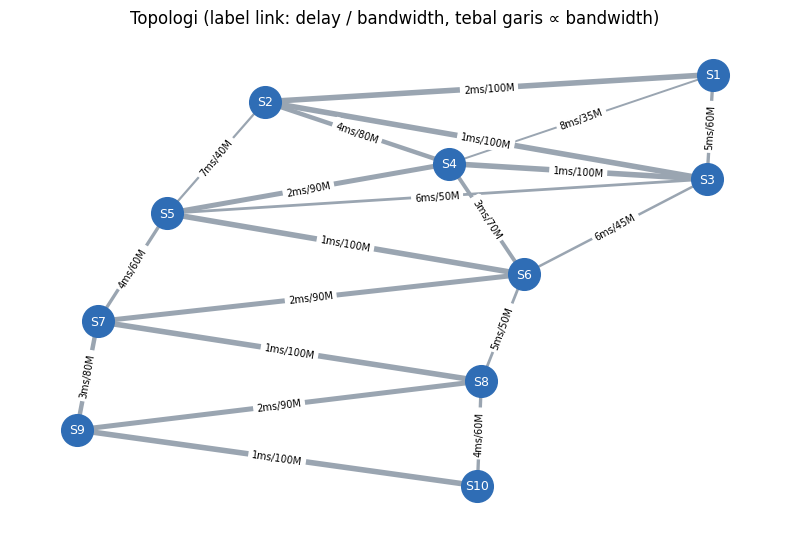

In [3]:
def load_topology(path):
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    G = nx.Graph()
    G.add_nodes_from(data["nodes"])
    for e in data["edges"]:
        G.add_edge(e["source"], e["target"], delay=float(e["delay"]),
                   bandwidth=float(e["bandwidth"]), loss=float(e["loss"]))
    return G

def random_topology(n_nodes=12, k_neighbors=3, area=1000.0, seed=42):
    """Gaya topology_generator.py: node acak pada area, dihubungkan ke k tetangga terdekat,
    delay diturunkan dari jarak, bandwidth & loss acak."""
    r = random.Random(seed)
    pos = {f"S{i + 1}": (r.uniform(0, area), r.uniform(0, area)) for i in range(n_nodes)}
    G = nx.Graph()
    for n, p in pos.items():
        G.add_node(n, pos=p)
    dist = lambda a, b: math.dist(pos[a], pos[b])
    def link(u, v):
        G.add_edge(u, v, delay=round(1 + 8 * dist(u, v) / area, 1),
                   bandwidth=float(r.choice([35, 40, 50, 60, 80, 90, 100])),
                   loss=round(r.uniform(0.001, 0.005), 4))
    for u in pos:
        for v in sorted((x for x in pos if x != u), key=lambda x: dist(u, x))[:k_neighbors]:
            link(u, v)
    comps = list(nx.connected_components(G))
    while len(comps) > 1:
        a, b = min(((x, y) for x in comps[0] for y in comps[1]), key=lambda p: dist(*p))
        link(a, b)
        comps = list(nx.connected_components(G))
    return G

G = load_topology(DATA / "topology.json") if TOPOLOGY_SOURCE == "file" else random_topology(**RANDOM_TOPO)
NODES = sorted(G.nodes(), key=lambda n: int(re.sub(r"\D", "", n) or 0))
assert len(NODES) <= 250, "maksimal 250 node (alamat 10.0.0.x)"

# pemetaan node graf → objek Mininet
SW   = {n: f"s{i + 1}" for i, n in enumerate(NODES)}          # switch
HOST = {n: f"h{i + 1}" for i, n in enumerate(NODES)}          # 1 host per switch
DPID = {n: i + 1 for i, n in enumerate(NODES)}
IP   = {n: f"10.0.0.{i + 1}" for i, n in enumerate(NODES)}
MAC  = {n: f"00:00:00:00:00:{i + 1:02x}" for i, n in enumerate(NODES)}

POS = nx.get_node_attributes(G, "pos") or nx.kamada_kawai_layout(G, weight=None)
edge_df = pd.DataFrame([dict(link=f"{u}-{v}", **d) for u, v, d in G.edges(data=True)])
print(f"{G.number_of_nodes()} switch, {G.number_of_edges()} link")
display(edge_df.head(10))

fig, ax = plt.subplots(figsize=(8, 5.5))
bw = [G[u][v]["bandwidth"] for u, v in G.edges()]
nx.draw_networkx_edges(G, POS, ax=ax, width=[b / 25 for b in bw], edge_color="#9aa5b1")
nx.draw_networkx_nodes(G, POS, ax=ax, node_color="#2f6db5", node_size=520)
nx.draw_networkx_labels(G, POS, ax=ax, font_color="white", font_size=9)
nx.draw_networkx_edge_labels(G, POS, ax=ax, font_size=7,
    edge_labels={(u, v): f"{d['delay']:g}ms/{d['bandwidth']:g}M" for u, v, d in G.edges(data=True)})
ax.set_title("Topologi (label link: delay / bandwidth, tebal garis ∝ bandwidth)")
ax.axis("off"); plt.tight_layout(); plt.savefig(RES / "topologi.png", dpi=150); plt.show()

## 2. Algoritma routing
| Algoritma | Bobot / tujuan |
|---|---|
| Hop-Count | jalur dengan jumlah hop paling sedikit (perilaku routing default/tanpa optimasi) |
| Dijkstra-Delay | minimum total delay |
| Widest-Path | memaksimalkan bandwidth bottleneck, tie-break delay terkecil |
| QoS-Dijkstra | biaya gabungan `w_d·delay/max_delay + w_b·min_bw/bw + w_l·loss/max_loss` |
| Q-Learning | agen RL per tujuan, reward = −biaya QoS link; jalur = kebijakan greedy hasil belajar |

Jalur all-pairs (90 pasangan × 5 algoritma) dihitung dalam 0.04 s
Q-Learning: 0 pasangan memakai fallback QoS-Dijkstra (kebijakan belum konvergen)
Q-Learning identik dengan optimum QoS-Dijkstra pada 100.0% pasangan


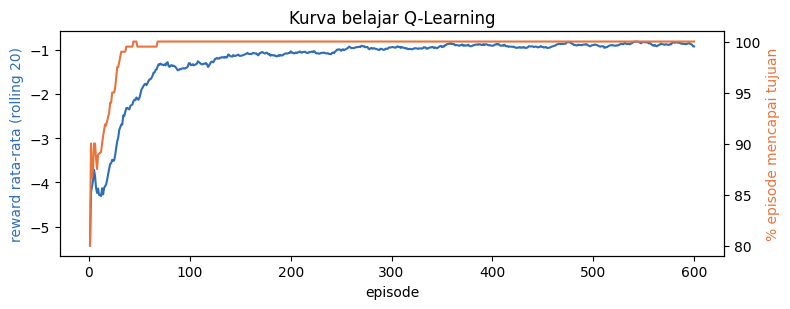

In [4]:
def path_edges(p):
    return list(zip(p[:-1], p[1:]))

def add_qos_cost(G, w=QOS_COST_WEIGHTS):
    ds = [d["delay"] for *_, d in G.edges(data=True)]
    bws = [d["bandwidth"] for *_, d in G.edges(data=True)]
    ls = [d["loss"] for *_, d in G.edges(data=True)]
    for u, v, d in G.edges(data=True):
        d["qos_cost"] = (w["delay"] * d["delay"] / max(ds)
                         + w["bandwidth"] * min(bws) / d["bandwidth"]
                         + w["loss"] * d["loss"] / max(max(ls), 1e-9))

add_qos_cost(G)

def route_hop(G, s, t):
    return nx.shortest_path(G, s, t)

def route_delay(G, s, t):
    return nx.dijkstra_path(G, s, t, weight="delay")

def route_widest(G, s, t):
    for thr in sorted({d["bandwidth"] for *_, d in G.edges(data=True)}, reverse=True):
        H = G.edge_subgraph([(u, v) for u, v, d in G.edges(data=True) if d["bandwidth"] >= thr])
        if s in H and t in H and nx.has_path(H, s, t):
            return nx.dijkstra_path(H, s, t, weight="delay")

def route_qos(G, s, t):
    return nx.dijkstra_path(G, s, t, weight="qos_cost")

def train_q_routing(G, dst, episodes, alpha, gamma, epsilon, epsilon_decay, epsilon_min, max_steps, seed=0):
    """Q-routing tabular untuk satu tujuan. State = node saat ini, aksi = tetangga berikutnya,
    reward = −qos_cost link. Dengan gamma=1 nilai Q konvergen ke −(biaya QoS menuju dst)."""
    r = random.Random(seed)
    starts = [n for n in G if n != dst]
    Q = {n: {v: 0.0 for v in G.neighbors(n)} for n in G}
    eps, curve = epsilon, []
    for ep in range(episodes):
        s, total, steps = r.choice(starts), 0.0, 0
        while s != dst and steps < max_steps:
            acts = list(Q[s])
            a = r.choice(acts) if r.random() < eps else max(acts, key=Q[s].get)
            reward = -G[s][a]["qos_cost"]
            future = 0.0 if a == dst else max(Q[a].values())
            Q[s][a] += alpha * (reward + gamma * future - Q[s][a])
            total += reward; s = a; steps += 1
        curve.append((ep + 1, total, s == dst))
        eps = max(epsilon_min, eps * epsilon_decay)
    return Q, curve

def q_greedy_path(Q, s, t, max_steps=50):
    path, seen = [s], {s}
    while path[-1] != t and len(path) <= max_steps:
        nxt = max(Q[path[-1]], key=Q[path[-1]].get)
        if nxt in seen:
            return None
        path.append(nxt); seen.add(nxt)
    return path if path[-1] == t else None

ROUTERS = {"Hop-Count": route_hop, "Dijkstra-Delay": route_delay,
           "Widest-Path": route_widest, "QoS-Dijkstra": route_qos}
PAIRS = [(s, t) for s in NODES for t in NODES if s != t]

routes, ql_curves, ql_fallback = {}, {}, 0
t0 = time.perf_counter()
for alg in ALGORITHMS:
    if alg == "Q-Learning":
        routes[alg] = {}
        for i, dst in enumerate(NODES):
            Q, curve = train_q_routing(G, dst, seed=SEED + i, **QL_PARAMS)
            ql_curves[dst] = curve
            for s in NODES:
                if s == dst:
                    continue
                p = q_greedy_path(Q, s, dst)
                if p is None:                     # kebijakan belum konvergen → fallback
                    p, ql_fallback = route_qos(G, s, dst), ql_fallback + 1
                routes[alg][(s, dst)] = p
    else:
        routes[alg] = {(s, t): ROUTERS[alg](G, s, t) for s, t in PAIRS}
print(f"Jalur all-pairs ({len(PAIRS)} pasangan × {len(ALGORITHMS)} algoritma) dihitung dalam {time.perf_counter() - t0:.2f} s")
print(f"Q-Learning: {ql_fallback} pasangan memakai fallback QoS-Dijkstra (kebijakan belum konvergen)")

same = np.mean([routes["Q-Learning"][p] == routes["QoS-Dijkstra"][p] for p in PAIRS]) * 100
print(f"Q-Learning identik dengan optimum QoS-Dijkstra pada {same:.1f}% pasangan")

# kurva belajar Q-Learning (rata-rata semua tujuan)
curve_df = pd.DataFrame([(dst, ep, rew, ok) for dst, c in ql_curves.items() for ep, rew, ok in c],
                        columns=["dst", "episode", "reward", "reached"])
cg = curve_df.groupby("episode").agg(reward=("reward", "mean"), reached=("reached", "mean"))
fig, ax1 = plt.subplots(figsize=(8, 3.2))
ax1.plot(cg.index, cg.reward.rolling(20, min_periods=1).mean(), color="#2f6db5")
ax1.set_xlabel("episode"); ax1.set_ylabel("reward rata-rata (rolling 20)", color="#2f6db5")
ax2 = ax1.twinx(); ax2.plot(cg.index, cg.reached.rolling(20, min_periods=1).mean() * 100, color="#e8743b")
ax2.set_ylabel("% episode mencapai tujuan", color="#e8743b")
ax1.set_title("Kurva belajar Q-Learning"); plt.tight_layout(); plt.savefig(RES / "qlearning_curve.png", dpi=150); plt.show()

## 3. Estimasi analitik + skor QoS
Model metrik sama dengan `metrics.py` dan `qos.py` pada proyek *software_defined_network* (tanpa jitter acak): delay = Σ delay link, throughput = bandwidth bottleneck × penalti hop, loss = 1 − Π(1 − loss link), skor QoS 0–100 (bobot delay 0.4, loss 0.3, throughput 0.3).

In [5]:
def analytic_metrics(G, path):
    e = path_edges(path)
    delay = sum(G[u][v]["delay"] for u, v in e)
    bott = min(G[u][v]["bandwidth"] for u, v in e)
    thr = bott * max(0.0, 1 - 0.03 * (len(e) - 1))
    loss = 1 - np.prod([1 - G[u][v]["loss"] for u, v in e])
    return dict(hops=len(e), delay_ms=delay, bottleneck_mbps=bott, throughput_mbps=thr, loss_pct=loss * 100)

def qos_score(m, G):
    delays = sorted((d["delay"] for *_, d in G.edges(data=True)), reverse=True)
    max_delay = sum(delays[: G.number_of_nodes() - 1])
    max_bw = max(d["bandwidth"] for *_, d in G.edges(data=True))
    ds = max(0, 100 - m["delay_ms"] / max_delay * 100)
    ls = max(0, 100 - m["loss_pct"] * 8)
    ts = min(100, m["throughput_mbps"] / max_bw * 100)
    return 0.4 * ds + 0.3 * ls + 0.3 * ts

def qos_class(score):
    return next(lbl for thr, lbl in [(85, "Excellent"), (70, "Good"), (50, "Fair"), (0, "Poor")] if score >= thr)

ana_rows = []
for alg in ALGORITHMS:
    for (s, t), p in routes[alg].items():
        m = analytic_metrics(G, p)
        m.update(algorithm=alg, src=s, dst=t, path="→".join(p), qos_cost=sum(G[u][v]["qos_cost"] for u, v in path_edges(p)))
        m["qos_score"] = qos_score(m, G)
        ana_rows.append(m)
analytic = pd.DataFrame(ana_rows)
summary_ana = analytic.groupby("algorithm")[["hops", "delay_ms", "bottleneck_mbps", "throughput_mbps", "loss_pct", "qos_cost", "qos_score"]].mean().loc[ALGORITHMS]
summary_ana["qos_class"] = summary_ana.qos_score.map(qos_class)
print("Rata-rata metrik analitik untuk semua pasangan:")
display(summary_ana.round(3))
analytic.to_csv(RES / "analitik_all_pairs.csv", index=False)

Rata-rata metrik analitik untuk semua pasangan:


,hops,delay_ms,bottleneck_mbps,throughput_mbps,loss_pct,qos_cost,qos_score,qos_class
algorithm,,,,,,,,
Hop-Count,1.889,7.578,61.000,59.712,0.543,1.018,80.424,Good
Dijkstra-Delay,2.911,5.289,81.778,77.478,0.432,0.846,87.888,Excellent
Widest-Path,3.667,5.289,92.000,84.773,0.508,0.936,89.897,Excellent
QoS-Dijkstra,2.911,5.289,81.778,77.478,0.432,0.846,87.888,Excellent
Q-Learning,2.911,5.289,81.778,77.478,0.432,0.846,87.888,Excellent


## 4. Aplikasi Ryu: `static_router.py`
Controller tidak menghitung jalur sendiri. Notebook menulis file JSON berisi flow rule per switch (`ipv4_src, ipv4_dst → out_port`); aplikasi Ryu memantau file tersebut, dan setiap kali `version` berubah ia menghapus flow lama, memasang flow baru, menunggu *barrier reply*, lalu menulis status ke file *state*. Aplikasi ini juga mengumpulkan **statistik port** (byte TX/RX) tiap detik ke CSV untuk menghitung utilisasi link.

ARP tidak dilewatkan ke controller: host diberi ARP statis (`net.staticArp()`), sehingga tidak ada flooding pada topologi mesh yang memiliki loop.

In [6]:
RYU_APP = r'''
"""
static_router.py - Ryu app (OpenFlow 1.3) untuk routing proaktif dari file JSON.

Format SDN_ROUTE_CONFIG:
  {"version": 3, "label": "QoS-Dijkstra",
   "flows": {"<dpid>": [{"src": "10.0.0.1", "dst": "10.0.0.7", "out_port": 2}, ...]}}

Variabel lingkungan:
  SDN_ROUTE_CONFIG    file konfigurasi routing (dipantau setiap 0.5 s)
  SDN_ROUTE_STATE     file status (versi yang sudah terpasang per switch)
  SDN_PORT_STATS      file CSV statistik port (kosong = nonaktif)
  SDN_STATS_INTERVAL  interval polling statistik port (detik)
"""
import csv
import json
import os
import time

from ryu.base import app_manager
from ryu.controller import ofp_event
from ryu.controller.handler import CONFIG_DISPATCHER, MAIN_DISPATCHER, DEAD_DISPATCHER, set_ev_cls
from ryu.lib import hub
from ryu.ofproto import ofproto_v1_3

CONFIG_PATH = os.environ.get("SDN_ROUTE_CONFIG", "/tmp/sdn_routes.json")
STATE_PATH = os.environ.get("SDN_ROUTE_STATE", CONFIG_PATH + ".state")
PORT_STATS_PATH = os.environ.get("SDN_PORT_STATS", "")
STATS_INTERVAL = float(os.environ.get("SDN_STATS_INTERVAL", "1.0"))
POLL_INTERVAL = 0.5
ROUTE_PRIORITY = 100
PORT_COLS = ["ts", "dpid", "port", "rx_packets", "tx_packets", "rx_bytes", "tx_bytes", "rx_dropped", "tx_dropped"]


class StaticRouter(app_manager.RyuApp):
    OFP_VERSIONS = [ofproto_v1_3.OFP_VERSION]

    def __init__(self, *args, **kwargs):
        super(StaticRouter, self).__init__(*args, **kwargs)
        self.datapaths = {}
        self.config = None
        self.config_mtime = None
        self.applied = {}
        self.pending = {}
        self.stats_writer = None
        if PORT_STATS_PATH:
            is_new = not os.path.exists(PORT_STATS_PATH)
            self.stats_file = open(PORT_STATS_PATH, "a", newline="")
            self.stats_writer = csv.writer(self.stats_file)
            if is_new:
                self.stats_writer.writerow(PORT_COLS)
                self.stats_file.flush()
            hub.spawn(self._stats_loop)
        hub.spawn(self._watch_config)

    # ------------------------------------------------------------ switch --
    @set_ev_cls(ofp_event.EventOFPSwitchFeatures, CONFIG_DISPATCHER)
    def _switch_features(self, ev):
        dp = ev.msg.datapath
        self.datapaths[dp.id] = dp
        self.logger.info("switch terhubung dpid=%s", dp.id)
        if self.config is not None:
            self._install(dp)

    @set_ev_cls(ofp_event.EventOFPStateChange, [MAIN_DISPATCHER, DEAD_DISPATCHER])
    def _state_change(self, ev):
        dp = ev.datapath
        if ev.state == DEAD_DISPATCHER and dp.id is not None:
            self.datapaths.pop(dp.id, None)
            self.applied.pop(dp.id, None)
            self._write_state()

    # ------------------------------------------------------------ config --
    def _read_config(self):
        try:
            mtime = os.path.getmtime(CONFIG_PATH)
        except OSError:
            return False
        if mtime == self.config_mtime:
            return False
        try:
            with open(CONFIG_PATH) as f:
                cfg = json.load(f)
        except (OSError, ValueError):
            return False                      # file sedang ditulis, coba lagi
        self.config_mtime = mtime
        if self.config is not None and cfg.get("version") == self.config.get("version"):
            return False
        self.config = cfg
        return True

    def _watch_config(self):
        while True:
            if self._read_config():
                self.logger.info("konfigurasi routing v%s (%s)", self.config.get("version"), self.config.get("label"))
                for dp in list(self.datapaths.values()):
                    self._install(dp)
            hub.sleep(POLL_INTERVAL)

    def _install(self, dp):
        ofp, parser = dp.ofproto, dp.ofproto_parser
        dp.send_msg(parser.OFPFlowMod(datapath=dp, command=ofp.OFPFC_DELETE, table_id=ofp.OFPTT_ALL,
                                      out_port=ofp.OFPP_ANY, out_group=ofp.OFPG_ANY, match=parser.OFPMatch()))
        rules = self.config.get("flows", {}).get(str(dp.id), [])
        for r in rules:
            match = parser.OFPMatch(eth_type=0x0800, ipv4_src=r["src"], ipv4_dst=r["dst"])
            inst = [parser.OFPInstructionActions(ofp.OFPIT_APPLY_ACTIONS,
                                                 [parser.OFPActionOutput(int(r["out_port"]))])]
            dp.send_msg(parser.OFPFlowMod(datapath=dp, priority=ROUTE_PRIORITY, match=match, instructions=inst))
        req = parser.OFPBarrierRequest(dp)
        dp.set_xid(req)
        self.pending[dp.id] = (req.xid, self.config.get("version"))
        dp.send_msg(req)

    @set_ev_cls(ofp_event.EventOFPBarrierReply, [CONFIG_DISPATCHER, MAIN_DISPATCHER])
    def _barrier_reply(self, ev):
        dp = ev.msg.datapath
        pend = self.pending.get(dp.id)
        if pend and pend[0] == ev.msg.xid:
            self.applied[dp.id] = pend[1]
            del self.pending[dp.id]
            self._write_state()

    def _write_state(self):
        state = {"version": self.config.get("version") if self.config else None,
                 "applied": {str(k): v for k, v in self.applied.items()},
                 "connected": sorted(self.datapaths), "time": time.time()}
        tmp = STATE_PATH + ".tmp"
        with open(tmp, "w") as f:
            json.dump(state, f)
        os.replace(tmp, STATE_PATH)

    # ------------------------------------------------------- port stats --
    def _stats_loop(self):
        while True:
            for dp in list(self.datapaths.values()):
                dp.send_msg(dp.ofproto_parser.OFPPortStatsRequest(dp, 0, dp.ofproto.OFPP_ANY))
            hub.sleep(STATS_INTERVAL)

    @set_ev_cls(ofp_event.EventOFPPortStatsReply, MAIN_DISPATCHER)
    def _port_stats_reply(self, ev):
        dp, now = ev.msg.datapath, time.time()
        for st in ev.msg.body:
            if st.port_no > dp.ofproto.OFPP_MAX:
                continue
            self.stats_writer.writerow([round(now, 3), dp.id, st.port_no, st.rx_packets, st.tx_packets,
                                        st.rx_bytes, st.tx_bytes, st.rx_dropped, st.tx_dropped])
        self.stats_file.flush()
'''
(RYU_DIR / "static_router.py").write_text(RYU_APP.lstrip(), encoding="utf-8")
print("Ryu app ditulis ke", RYU_DIR / "static_router.py")

Ryu app ditulis ke /mnt/c/Users/wirar/OneDrive/Documents/GitHub/sdn/ryu_apps/static_router.py


## 5. Menyiapkan emulasi (Mininet + controller Ryu)
Pada mode `mininet`: setiap switch `sN` (dpid = N) mendapat satu host `hN` (10.0.0.N). Link antar switch memakai `TCLink` dengan delay, bandwidth (HTB), dan loss (netem) sesuai topologi. Pada mode `sim` sel ini hanya menyiapkan model.

In [7]:
ROUTE_CFG = RUNTIME / "routes.json"
ROUTE_STATE = RUNTIME / "routes_state.json"
PORT_STATS = RUNTIME / "port_stats.csv"
net, ryu_proc, PORTMAP, route_version = None, None, {}, 0

def start_ryu():
    subprocess.run(["fuser", "-k", f"{OF_PORT}/tcp"], capture_output=True)
    for f in (ROUTE_STATE, PORT_STATS):
        f.unlink(missing_ok=True)
    env = dict(os.environ, SDN_ROUTE_CONFIG=str(ROUTE_CFG), SDN_ROUTE_STATE=str(ROUTE_STATE),
               SDN_PORT_STATS=str(PORT_STATS), SDN_STATS_INTERVAL=str(PORT_STATS_INTERVAL))
    log = open(RUNTIME / "ryu.log", "w")
    proc = subprocess.Popen([ryu_manager_path(), "--ofp-tcp-listen-port", str(OF_PORT),
                             str(RYU_DIR / "static_router.py")], stdout=log, stderr=subprocess.STDOUT, env=env)
    time.sleep(2.5)
    if proc.poll() is not None:
        raise RuntimeError("ryu-manager berhenti — lihat " + str(RUNTIME / "ryu.log"))
    return proc

def build_mininet(G):
    from functools import partial
    from mininet.net import Mininet
    from mininet.node import RemoteController, OVSSwitch
    from mininet.link import TCLink
    from mininet.clean import cleanup
    from mininet.log import setLogLevel
    setLogLevel("warning")
    cleanup()
    net = Mininet(switch=partial(OVSSwitch, protocols="OpenFlow13", datapath=OVS_DATAPATH),
                  link=TCLink, controller=None, autoSetMacs=False, build=False)
    net.addController("c0", controller=RemoteController, ip="127.0.0.1", port=OF_PORT)
    for n in NODES:
        s = net.addSwitch(SW[n], dpid=f"{DPID[n]:016x}")
        h = net.addHost(HOST[n], ip=f"{IP[n]}/24", mac=MAC[n])
        net.addLink(h, s, bw=1000)                     # port 1 tiap switch = host
    for u, v, d in G.edges(data=True):
        net.addLink(SW[u], SW[v], bw=d["bandwidth"], delay=f"{d['delay']}ms", loss=d["loss"] * 100)
    net.build()
    return net

def port_map(net):
    pm = {}
    for link in net.links:
        i1, i2 = link.intf1, link.intf2
        pm[(i1.node.name, i2.node.name)] = i1.node.ports[i1]
        pm[(i2.node.name, i1.node.name)] = i2.node.ports[i2]
    return pm

def routes_to_flows(route_dict):
    flows = defaultdict(list)
    for (s, t), path in route_dict.items():
        for i, n in enumerate(path):
            nxt = SW[path[i + 1]] if i + 1 < len(path) else HOST[t]
            flows[str(DPID[n])].append({"src": IP[s], "dst": IP[t], "out_port": PORTMAP[(SW[n], nxt)]})
    return dict(flows)

def apply_routes(label, route_dict, timeout=30):
    """Tulis flow rule ke JSON lalu tunggu Ryu memasangnya ke semua switch."""
    global route_version
    if MODE != "mininet":
        return
    route_version += 1
    cfg = {"version": route_version, "label": label, "flows": routes_to_flows(route_dict)}
    tmp = ROUTE_CFG.with_suffix(".tmp")
    tmp.write_text(json.dumps(cfg))
    os.replace(tmp, ROUTE_CFG)
    t_end = time.time() + timeout
    while time.time() < t_end:
        try:
            st = json.loads(ROUTE_STATE.read_text())
            if sum(v == route_version for v in st["applied"].values()) == len(NODES):
                return
        except (OSError, ValueError, KeyError):
            pass
        time.sleep(0.3)
    raise TimeoutError(f"Ryu belum memasang routing v{route_version} — cek {RUNTIME / 'ryu.log'}")

def shutdown():
    global net, ryu_proc
    if net is not None:
        try:
            net.stop()
        except Exception:
            pass
        net = None
    if ryu_proc is not None:
        ryu_proc.terminate()
        try:
            ryu_proc.wait(timeout=5)
        except subprocess.TimeoutExpired:
            ryu_proc.kill()
        ryu_proc = None

if MODE == "mininet":
    atexit.register(shutdown)
    shutdown()
    net = build_mininet(G)
    PORTMAP = port_map(net)
    ROUTE_CFG.write_text(json.dumps({"version": 0, "label": "init", "flows": {}}))
    ryu_proc = start_ryu()
    net.start()
    net.staticArp()
    apply_routes("QoS-Dijkstra", routes["QoS-Dijkstra"])
    loss = net.ping([net.get(HOST[NODES[0]]), net.get(HOST[NODES[-1]])], timeout=2)
    print(f"Emulasi aktif: {len(net.switches)} switch, {len(net.hosts)} host, {len(net.links)} link. Ping uji loss={loss:.0f}%")
else:
    print("Mode simulasi: tidak ada Mininet/Ryu yang dijalankan.")

Unable to contact the remote controller at 127.0.0.1:6653
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001 is big. Consider r2q change.
*** Error: Warning: sch_htb: quantum of class 50001

Emulasi aktif: 10 switch, 10 host, 30 link. Ping uji loss=0%


## 6. Pengukuran kinerja tiap algoritma
Untuk tiap algoritma: pasang routing all-pairs → ukur `ping` (RTT, loss) pada pasangan terjauh dan `iperf` TCP (throughput).

In [8]:
MSS_BYTES = 1460

def tcp_limit_mbps(rtt_ms, p):
    """Batas throughput TCP model Mathis: MSS/RTT · 1.22/√p."""
    if p <= 0:
        return float("inf")
    return MSS_BYTES * 8 / (rtt_ms / 1000) * 1.22 / math.sqrt(p) / 1e6

def path_loss(path):
    return 1 - np.prod([1 - G[u][v]["loss"] for u, v in path_edges(path)])

def sim_ping(path, count):
    one_way = sum(G[u][v]["delay"] for u, v in path_edges(path)) + 0.03 * len(path)
    rtts = 2 * one_way + rng.gamma(2.0, 0.08, count)
    lost = rng.binomial(count, 1 - (1 - path_loss(path)) ** 2)
    return dict(rtt_avg_ms=float(rtts.mean()), rtt_mdev_ms=float(rtts.std()), ping_loss_pct=100 * lost / count)

def sim_iperf(path):
    rtt = 2 * sum(G[u][v]["delay"] for u, v in path_edges(path)) + 0.2
    bott = min(G[u][v]["bandwidth"] for u, v in path_edges(path))
    return min(0.95 * bott, tcp_limit_mbps(rtt, path_loss(path))) * rng.uniform(0.9, 1.0)

def mn_ping(s, t, count):
    out = net.get(HOST[s]).cmd(f"ping -c {count} -i 0.2 -W 2 {IP[t]}")
    loss = re.search(r"([\d.]+)% packet loss", out)
    m = re.search(r"= ([\d.]+)/([\d.]+)/([\d.]+)/([\d.]+) ms", out)
    return dict(rtt_avg_ms=float(m.group(2)) if m else np.nan, rtt_mdev_ms=float(m.group(4)) if m else np.nan,
                ping_loss_pct=float(loss.group(1)) if loss else 100.0)

def mn_iperf(s, t, seconds, port=5001):
    srv, cli = net.get(HOST[t]), net.get(HOST[s])
    srv.cmd(f"iperf -s -p {port} > /dev/null 2>&1 &")
    time.sleep(0.5)
    out = cli.cmd(f"iperf -c {IP[t]} -p {port} -t {seconds} -f m")
    srv.cmd(f"pkill -f 'iperf -s -p {port}'")
    vals = re.findall(r"([\d.]+) Mbits/sec", out)
    return float(vals[-1]) if vals else np.nan

# pasangan terjauh (berdasarkan hop) dengan sumber berbeda
hop_len = {p: len(routes["Hop-Count"][p]) - 1 for p in PAIRS}
MEASURE_PAIRS, used = [], set()
for p in sorted(PAIRS, key=lambda p: (-hop_len[p], -analytic_metrics(G, routes["Dijkstra-Delay"][p])["delay_ms"])):
    if p[0] not in used and (p[1], p[0]) not in MEASURE_PAIRS:
        MEASURE_PAIRS.append(p); used.add(p[0])
    if len(MEASURE_PAIRS) == N_MEASURE_PAIRS:
        break
IPERF_PAIRS = MEASURE_PAIRS[:N_IPERF_PAIRS]
print("Pasangan diukur:", MEASURE_PAIRS)

meas_rows = []
for alg in ALGORITHMS:
    apply_routes(alg, routes[alg])
    for s, t in MEASURE_PAIRS:
        path = routes[alg][(s, t)]
        r = mn_ping(s, t, PING_COUNT) if MODE == "mininet" else sim_ping(path, PING_COUNT)
        r["throughput_mbps"] = np.nan
        if (s, t) in IPERF_PAIRS:
            r["throughput_mbps"] = mn_iperf(s, t, IPERF_SECONDS) if MODE == "mininet" else sim_iperf(path)
        r.update(algorithm=alg, src=s, dst=t, path="→".join(path), hops=len(path) - 1)
        meas_rows.append(r)
    print(f"✔ {alg:<15} selesai diukur")

meas = pd.DataFrame(meas_rows)
meas.to_csv(RES / "pengukuran_per_pasangan.csv", index=False)
display(meas[["algorithm", "src", "dst", "hops", "path", "rtt_avg_ms", "ping_loss_pct", "throughput_mbps"]].round(2))

Pasangan diukur: [('S1', 'S10'), ('S9', 'S1'), ('S2', 'S10'), ('S3', 'S10'), ('S8', 'S1'), ('S4', 'S10')]
✔ Hop-Count       selesai diukur
✔ Dijkstra-Delay  selesai diukur
✔ Widest-Path     selesai diukur
✔ QoS-Dijkstra    selesai diukur
✔ Q-Learning      selesai diukur


,algorithm,src,dst,hops,path,rtt_avg_ms,ping_loss_pct,throughput_mbps
0,Hop-Count,S1,S10,4,S1→S4→S6→S8→S10,42.05,0.0,5.60
1,Hop-Count,S9,S1,4,S9→S7→S5→S3→S1,35.43,5.0,7.31
2,Hop-Count,S2,S10,4,S2→S4→S6→S8→S10,33.81,0.0,6.69
3,Hop-Count,S3,S10,3,S3→S6→S8→S10,31.45,0.0,NaN
4,Hop-Count,S8,S1,3,S8→S6→S3→S1,33.35,0.0,NaN
5,Hop-Count,S4,S10,3,S4→S6→S8→S10,25.10,0.0,NaN
6,Dijkstra-Delay,S1,S10,7,S1→S2→S3→S4→S6→S7→S9→S10,29.29,0.0,12.10
7,Dijkstra-Delay,S9,S1,6,S9→S7→S6→S4→S3→S2→S1,26.36,0.0,14.10
8,Dijkstra-Delay,S2,S10,6,S2→S3→S4→S6→S7→S9→S10,24.55,0.0,9.40
9,Dijkstra-Delay,S3,S10,5,S3→S4→S6→S7→S9→S10,22.03,0.0,NaN


Ringkasan (mininet) — rata-rata atas pasangan yang diukur:


,hops,rtt_ms,jitter_ms,loss_pct,throughput_mbps,rtt_analitik_ms,qos_score_analitik,qos_class
algorithm,,,,,,,,
Hop-Count,3.50,33.53,0.49,0.83,6.53,32.33,66.82,Fair
Dijkstra-Delay,5.67,24.05,0.67,0.00,11.87,21.67,77.18,Good
Widest-Path,7.50,24.88,0.46,0.83,9.00,21.67,80.42,Good
QoS-Dijkstra,5.67,24.16,0.44,0.00,8.65,21.67,77.18,Good
Q-Learning,5.67,23.93,0.52,1.67,9.21,21.67,77.18,Good


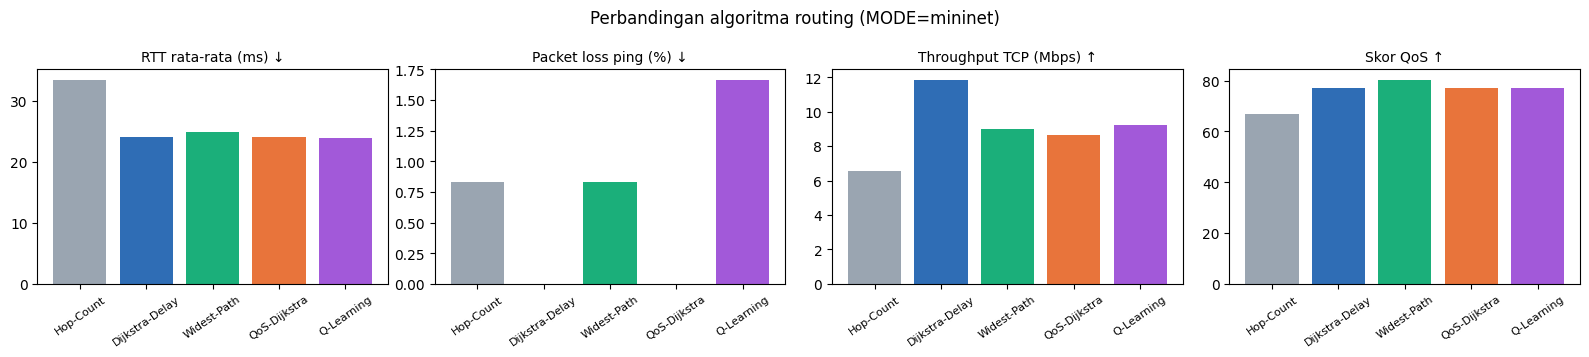

In [9]:
summary = meas.groupby("algorithm").agg(hops=("hops", "mean"), rtt_ms=("rtt_avg_ms", "mean"),
                                        jitter_ms=("rtt_mdev_ms", "mean"), loss_pct=("ping_loss_pct", "mean"),
                                        throughput_mbps=("throughput_mbps", "mean")).loc[ALGORITHMS]
ana_mp = analytic[analytic.apply(lambda r: (r.src, r.dst) in MEASURE_PAIRS, axis=1)]
summary["rtt_analitik_ms"] = ana_mp.groupby("algorithm").delay_ms.mean().loc[ALGORITHMS] * 2
summary["qos_score_analitik"] = ana_mp.groupby("algorithm").qos_score.mean().loc[ALGORITHMS]
summary["qos_class"] = summary.qos_score_analitik.map(qos_class)
summary.to_csv(RES / "ringkasan_algoritma.csv")
print(f"Ringkasan ({MODE}) — rata-rata atas pasangan yang diukur:")
display(summary.round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
colors = ["#9aa5b1", "#2f6db5", "#1baf7a", "#e8743b", "#a259d9"]
for ax, (col, title) in zip(axes, [("rtt_ms", "RTT rata-rata (ms) ↓"), ("loss_pct", "Packet loss ping (%) ↓"),
                                   ("throughput_mbps", "Throughput TCP (Mbps) ↑"), ("qos_score_analitik", "Skor QoS ↑")]):
    ax.bar(summary.index, summary[col], color=colors[: len(summary)])
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", rotation=35, labelsize=8)
fig.suptitle(f"Perbandingan algoritma routing (MODE={MODE})")
plt.tight_layout(); plt.savefig(RES / "perbandingan_algoritma.png", dpi=150); plt.show()

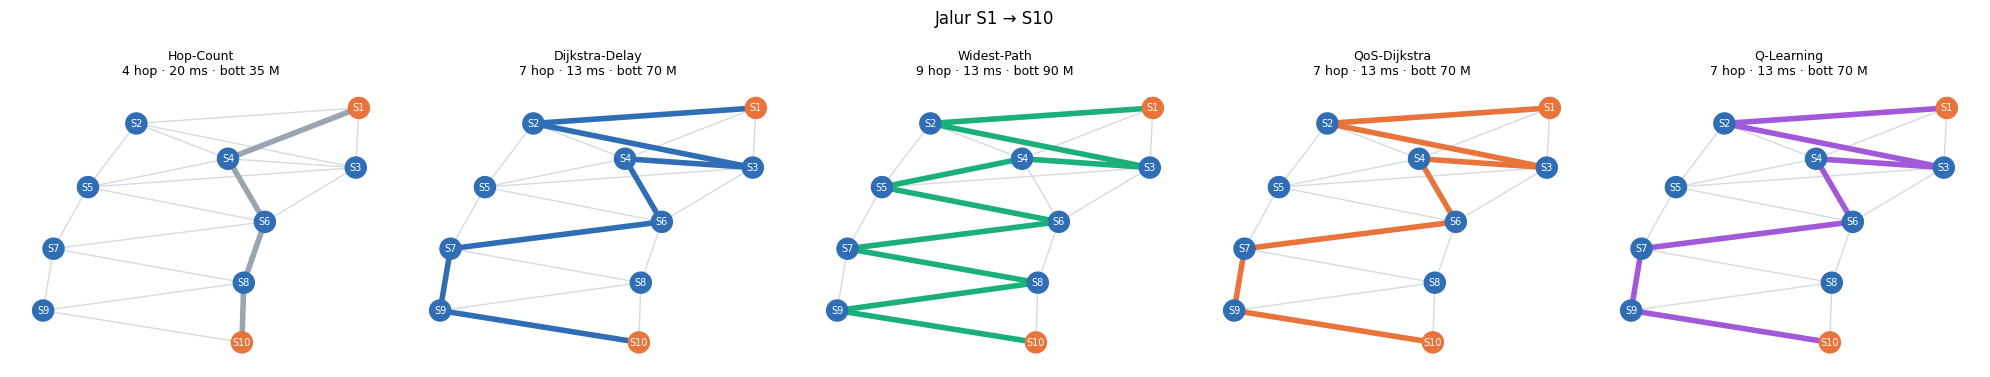

In [10]:
# visualisasi jalur tiap algoritma untuk pasangan terjauh
s0, t0_ = MEASURE_PAIRS[0]
fig, axes = plt.subplots(1, len(ALGORITHMS), figsize=(4 * len(ALGORITHMS), 3.8))
for ax, alg, c in zip(axes, ALGORITHMS, colors):
    p = routes[alg][(s0, t0_)]
    nx.draw_networkx_edges(G, POS, ax=ax, edge_color="#d5dbe1")
    nx.draw_networkx_edges(G, POS, ax=ax, edgelist=path_edges(p), edge_color=c, width=4)
    nx.draw_networkx_nodes(G, POS, ax=ax, node_size=230, node_color=["#e8743b" if n in (s0, t0_) else "#2f6db5" for n in G])
    nx.draw_networkx_labels(G, POS, ax=ax, font_size=7, font_color="white")
    m = analytic_metrics(G, p)
    ax.set_title(f"{alg}\n{m['hops']} hop · {m['delay_ms']:g} ms · bott {m['bottleneck_mbps']:g} M", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Jalur {s0} → {t0_}"); plt.tight_layout(); plt.savefig(RES / "jalur_per_algoritma.png", dpi=150); plt.show()

## 7. Traffic engineering: load balancing beberapa flow sekaligus
Beberapa flow UDP berlaju tetap `LB_DEMAND_MBPS` (iperf `-u -b`) dijalankan **bersamaan**. Strategi jalur terpendek cenderung menumpuk flow pada link yang sama sehingga link tersebut kelebihan beban (paket dibuang), sedangkan strategi **Load-Aware** memilih, untuk tiap flow, jalur dari *k*-shortest-path yang meminimalkan utilisasi link maksimum setelah flow tersebut ditambahkan.

Metrik: throughput yang benar-benar diterima, packet loss UDP, beban tawaran maksimum per link (*offered load*, bisa > 1), dan utilisasi link terukur — di mode `mininet` dari **statistik port** yang dikumpulkan Ryu, di mode `sim` dari alokasi *max-min fair* (progressive filling).

In [11]:
def k_shortest(s, t, k):
    return list(itertools.islice(nx.shortest_simple_paths(G, s, t, weight="delay"), k))

def lb_assign(flows, strategy, demand=LB_DEMAND_MBPS, k=LB_K_PATHS):
    load, out = defaultdict(float), {}
    for s, t in flows:
        if strategy == "Hop-Count":
            p = route_hop(G, s, t)
        elif strategy == "Dijkstra-Delay":
            p = route_delay(G, s, t)
        else:
            p = min(k_shortest(s, t, k), key=lambda c: (
                max((load[e] + demand) / G.edges[e]["bandwidth"] for e in path_edges(c)),
                sum(G.edges[e]["delay"] for e in path_edges(c))))
        for e in path_edges(p):
            load[e] += demand
        out[(s, t)] = p
    return out

def maxmin_fair(paths, caps):
    """Progressive filling: alokasi max-min fair untuk flow pada link berarah berkapasitas."""
    rate = {f: 0.0 for f in paths}
    remaining = {e: c for e, c in caps.items()}
    active = set(paths)
    while active:
        users = defaultdict(list)
        for f in active:
            for e in path_edges(paths[f]):
                users[e].append(f)
        inc = min([remaining[e] / len(fs) for e, fs in users.items()] +
                  [FLOW_CAP[f] - rate[f] for f in active])
        for f in active:
            rate[f] += inc
        for e, fs in users.items():
            remaining[e] -= inc * len(fs)
        done = {f for e, fs in users.items() if remaining[e] <= 1e-9 for f in fs}
        done |= {f for f in active if FLOW_CAP[f] - rate[f] <= 1e-9}
        active -= done
    return rate

def link_util_from_port_stats(t_start, t_end):
    ps = pd.read_csv(PORT_STATS)
    ps = ps[(ps.ts >= t_start) & (ps.ts <= t_end)]
    util = {}
    for u, v, d in G.edges(data=True):
        for a, b in ((u, v), (v, u)):
            port = PORTMAP[(SW[a], SW[b])]
            x = ps[(ps.dpid == DPID[a]) & (ps.port == port)].sort_values("ts")
            if len(x) >= 2:
                mbps = (x.tx_bytes.iloc[-1] - x.tx_bytes.iloc[0]) * 8 / (x.ts.iloc[-1] - x.ts.iloc[0]) / 1e6
                util[(a, b)] = mbps / d["bandwidth"]
    return util

# pilih flow: pasangan berjauhan dengan endpoint berbeda
LB_FLOWS, used = [], set()
for p in sorted(PAIRS, key=lambda p: -hop_len[p]):
    if p[0] not in used and p[1] not in used:
        LB_FLOWS.append(p); used |= {p[0], p[1]}
    if len(LB_FLOWS) == LB_N_FLOWS:
        break
print("Flow load balancing:", LB_FLOWS)

lb_rows, lb_util = [], {}
for strat in LB_STRATEGIES:
    paths = lb_assign(LB_FLOWS, strat)
    offered = defaultdict(float)
    for p in paths.values():
        for e in path_edges(p):
            offered[e] += LB_DEMAND_MBPS / G.edges[e]["bandwidth"]
    if MODE == "mininet":
        rt = dict(routes["QoS-Dijkstra"])
        for (s, t), p in paths.items():
            rt[(s, t)], rt[(t, s)] = p, p[::-1]
        apply_routes(f"LB-{strat}", rt)
        for i, (s, t) in enumerate(LB_FLOWS):
            net.get(HOST[t]).cmd(f"iperf -s -u -p {5101 + i} > /dev/null 2>&1 &")
        time.sleep(0.7)
        t_start = time.time()
        procs = [net.get(HOST[s]).popen(["iperf", "-c", IP[t], "-u", "-b", f"{LB_DEMAND_MBPS}M", "-p", str(5101 + i),
                                         "-t", str(LB_IPERF_SECONDS), "-f", "m"]) for i, (s, t) in enumerate(LB_FLOWS)]
        rates, losses = {}, {}
        for f, pr in zip(LB_FLOWS, procs):
            out = pr.communicate()[0].decode(errors="ignore")
            vals = re.findall(r"([\d.]+) Mbits/sec", out)          # baris terakhir = Server Report
            lossm = re.findall(r"\(([\d.]+)%\)", out)
            rates[f] = float(vals[-1]) if vals else 0.0
            losses[f] = float(lossm[-1]) if lossm else np.nan
        t_end = time.time()
        for i, (s, t) in enumerate(LB_FLOWS):
            net.get(HOST[t]).cmd(f"pkill -f 'iperf -s -u -p {5101 + i}'")
        time.sleep(PORT_STATS_INTERVAL * 1.5)
        util = link_util_from_port_stats(t_start + 1, t_end - 0.5)
    else:
        caps = {}
        for u, v, d in G.edges(data=True):
            caps[(u, v)] = caps[(v, u)] = d["bandwidth"]
        FLOW_CAP = {f: LB_DEMAND_MBPS for f in paths}             # UDP: laju dibatasi demand
        alloc = maxmin_fair(paths, caps)
        rates = {f: alloc[f] * (1 - path_loss(paths[f])) * rng.uniform(0.985, 1.0) for f in paths}
        losses = {f: 100 * (1 - rates[f] / LB_DEMAND_MBPS) for f in paths}
        util = defaultdict(float)
        for f, p in paths.items():
            for e in path_edges(p):
                util[e] += alloc[f] / G.edges[e]["bandwidth"]
    lb_util[strat] = dict(util)
    r = np.array([rates[f] for f in LB_FLOWS])
    ratio = r / LB_DEMAND_MBPS
    lb_rows.append(dict(strategy=strat, total_throughput_mbps=r.sum(), min_flow_mbps=r.min(),
                        mean_loss_pct=np.nanmean([losses[f] for f in LB_FLOWS]),
                        jain_fairness=ratio.sum() ** 2 / (len(ratio) * (ratio ** 2).sum()) if ratio.sum() else 0,
                        max_offered_load=max(offered.values()), max_link_util=max(util.values()) if util else np.nan,
                        paths=" | ".join("→".join(p) for p in paths.values())))
    print(f"✔ {strat:<15} diterima={r.sum():6.1f}/{LB_DEMAND_MBPS * len(r)} Mbps  per-flow={np.round(r, 1)}  "
          f"beban maks link={max(offered.values()):.2f}")

lb = pd.DataFrame(lb_rows).set_index("strategy")
lb.to_csv(RES / "load_balancing.csv")
display(lb.round(3))

Flow load balancing: [('S1', 'S9'), ('S2', 'S10'), ('S3', 'S7'), ('S4', 'S8')]
✔ Hop-Count       diterima= 107.5/160 Mbps  per-flow=[31.  20.  28.  28.5]  beban maks link=1.60
✔ Dijkstra-Delay  diterima=  68.1/160 Mbps  per-flow=[20.2 19.2 13.5 15.2]  beban maks link=2.29
✔ Load-Aware      diterima= 127.4/160 Mbps  per-flow=[34.  29.  25.4 39. ]  beban maks link=1.20


,total_throughput_mbps,min_flow_mbps,mean_loss_pct,jain_fairness,max_offered_load,max_link_util,paths
strategy,,,,,,,
Hop-Count,107.5,20.0,0.0,0.977,1.600,1.000,S1→S2→S5→S7→S9 | S2→S4→S6→S8→S10 | S3→S5→S7 | ...
Dijkstra-Delay,68.1,13.5,0.0,0.974,2.286,0.999,S1→S2→S3→S4→S6→S7→S9 | S2→S3→S4→S6→S7→S9→S10 |...
Load-Aware,127.4,25.4,0.0,0.975,1.200,1.002,S1→S2→S3→S4→S5→S6→S7→S8→S9 | S2→S3→S4→S6→S7→S9...


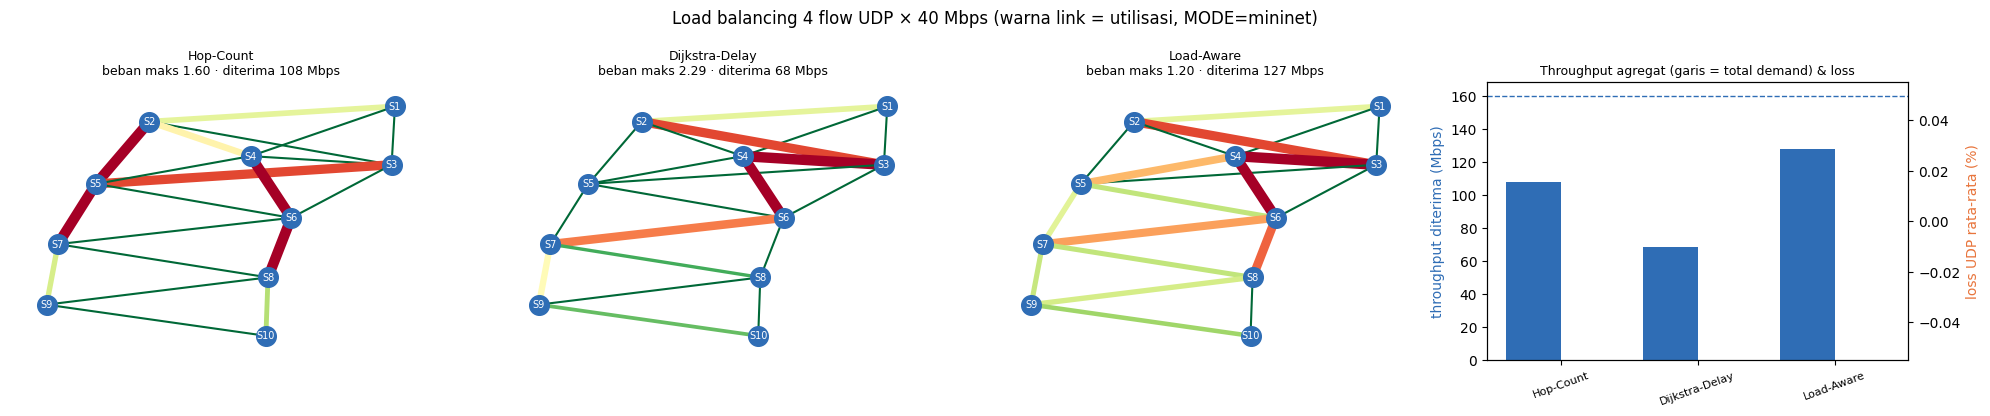

In [12]:
fig, axes = plt.subplots(1, len(LB_STRATEGIES) + 1, figsize=(5 * (len(LB_STRATEGIES) + 1), 4.2))
for ax, strat in zip(axes, LB_STRATEGIES):
    u = lb_util[strat]
    val = [max(u.get((a, b), 0), u.get((b, a), 0)) for a, b in G.edges()]
    nx.draw_networkx_edges(G, POS, ax=ax, edge_color=val, edge_cmap=plt.cm.RdYlGn_r, edge_vmin=0, edge_vmax=1,
                           width=[1.5 + 6 * v for v in val])
    nx.draw_networkx_nodes(G, POS, ax=ax, node_size=200, node_color="#2f6db5")
    nx.draw_networkx_labels(G, POS, ax=ax, font_size=7, font_color="white")
    ax.set_title(f"{strat}\nbeban maks {lb.loc[strat, 'max_offered_load']:.2f} · diterima {lb.loc[strat, 'total_throughput_mbps']:.0f} Mbps", fontsize=9)
    ax.axis("off")
ax = axes[-1]
x = np.arange(len(LB_STRATEGIES))
ax.bar(x - 0.2, lb.total_throughput_mbps, 0.4, color="#2f6db5")
ax.axhline(LB_DEMAND_MBPS * LB_N_FLOWS, color="#2f6db5", ls="--", lw=1)
ax2 = ax.twinx(); ax2.bar(x + 0.2, lb.mean_loss_pct, 0.4, color="#e8743b")
ax.set_xticks(x); ax.set_xticklabels(LB_STRATEGIES, rotation=20, fontsize=8)
ax.set_ylabel("throughput diterima (Mbps)", color="#2f6db5"); ax2.set_ylabel("loss UDP rata-rata (%)", color="#e8743b")
ax.set_title("Throughput agregat (garis = total demand) & loss", fontsize=9)
plt.suptitle(f"Load balancing {LB_N_FLOWS} flow UDP × {LB_DEMAND_MBPS} Mbps (warna link = utilisasi, MODE={MODE})")
plt.tight_layout(); plt.savefig(RES / "load_balancing.png", dpi=150); plt.show()

## 8. Penutup
Hentikan emulasi (Mininet + Ryu) dan lihat berkas hasil. Bila kernel sempat terhenti di tengah jalan, jalankan `sudo mn -c` di terminal untuk membersihkan sisa interface/bridge.

In [13]:
shutdown()
print("Emulasi dihentikan." if MODE == "mininet" else "Mode simulasi selesai.")
for f in sorted(RES.iterdir()):
    print(f"  {f.relative_to(BASE)}  ({f.stat().st_size / 1024:.1f} KB)")

Emulasi dihentikan.
  results/01_optimasi/analitik_all_pairs.csv  (46.8 KB)
  results/01_optimasi/jalur_per_algoritma.png  (145.5 KB)
  results/01_optimasi/load_balancing.csv  (0.6 KB)
  results/01_optimasi/load_balancing.png  (194.4 KB)
  results/01_optimasi/pengukuran_per_pasangan.csv  (2.2 KB)
  results/01_optimasi/perbandingan_algoritma.png  (69.4 KB)
  results/01_optimasi/qlearning_curve.png  (52.6 KB)
  results/01_optimasi/ringkasan_algoritma.csv  (0.7 KB)
  results/01_optimasi/topologi.png  (124.8 KB)


### Ide eksperimen lanjutan
1. Ubah `QOS_COST_WEIGHTS` (mis. bobot loss lebih besar) lalu bandingkan jalur QoS-Dijkstra & Q-Learning.
2. Kurangi `QL_PARAMS['episodes']` untuk melihat Q-Learning yang belum konvergen (jumlah fallback naik).
3. Gunakan `TOPOLOGY_SOURCE = "random"` dengan 15–20 node.
4. Naikkan `LB_N_FLOWS` / `LB_DEMAND_MBPS` dan amati selisih strategi Load-Aware vs jalur terpendek; coba juga flow TCP (hapus `-u -b`) — throughput TCP di topologi ber-loss lebih dibatasi loss daripada kapasitas.
5. Di mode `mininet`, ubah delay/loss sebuah link saat emulasi berjalan (`net.get('s3').cmd('tc qdisc ...')`) lalu ukur ulang tanpa mengubah routing — inilah alasan perlunya routing adaptif.